In [202]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter

In [2]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"}, event_types={'scalars'})

In [19]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [47]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_episode"] / data_pivot["observation/progress_metres"]
data_pivot = data_pivot.reset_index()
data_pivot

tag,step,run_category,run_seed,aux_weight,aux/r2_score_angular_velocity_y,aux/r2_score_track_curvature_0_50,aux/r2_score_track_curvature_1_00,aux/r2_score_track_curvature_1_50,aux/r2_score_track_curvature_2_00,aux/r2_score_track_curvature_2_50,...,reward/mean,reward/progress,reward/step_penalty,time/epochs,time/gae,time/rollout,time/save_rollout_buffer,time/stack_rollout,total_loss,collision/per_progress_metres
0,0,all,s0,0.1,-36.760838,-0.107802,-0.459932,-0.314270,-0.064969,-1.789895,...,0.000996,0.002135,0.0,10.008658,1.938310,12.522568,0.000975,0.344169,2.963941,466.448348
1,0,all,s0,0.3,-39.456612,-0.098814,-0.144638,-0.305841,-0.099307,-1.768703,...,0.000972,0.001949,0.0,8.474113,2.592816,10.867826,0.000894,0.505444,9.179862,510.380081
2,0,all,s0,1,-36.120346,-0.064812,-0.469869,-0.185669,-0.138459,-1.126899,...,0.001084,0.002060,0.0,11.106289,2.015859,9.606984,0.000789,0.332589,30.725483,483.326112
3,0,all,s1,0.1,-1.409436,0.002055,-1.306015,-0.040239,-0.012051,-0.054478,...,-0.002604,-0.000976,0.0,13.932582,2.415828,11.515951,0.000979,0.326533,2.971479,-1011.650748
4,0,all,s1,0.3,-1.480806,0.003906,-1.034779,-0.047584,-0.018308,-0.181313,...,-0.001854,-0.000796,0.0,14.766748,2.572167,10.900142,0.001178,0.479866,9.078182,-1243.862306
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63506,599,wheel_slip_rear_lateral,s1,0.3,-0.198631,0.015063,-0.128525,-0.121779,-0.027746,-0.014898,...,0.176496,0.176659,0.0,11.958018,2.316306,12.053017,0.099643,0.384980,0.201669,1.029123
63507,599,wheel_slip_rear_lateral,s1,1,-2.463015,-0.557006,-0.880546,-0.781169,-0.308356,-0.821525,...,0.080987,0.086196,0.0,11.142289,2.441858,14.239220,0.109430,0.316626,1.812873,11.058696
63508,599,wheel_slip_rear_lateral,s2,0.1,-3.207504,-0.189488,-0.267998,-0.039256,-1.767026,-0.320978,...,0.146979,0.147955,0.0,10.590935,1.374351,12.967243,0.055672,0.466701,0.393427,3.118006
63509,599,wheel_slip_rear_lateral,s2,0.3,-2.437889,-0.302804,-0.222606,-0.081266,-3.232392,-0.520291,...,0.077074,0.078051,0.0,12.143515,1.450007,11.135865,0.068160,0.324646,0.662839,9.599004


In [177]:
IMPORTANT_STATS = [
    "reward/mean",
    "observation/progress_metres",
    "observation/forward_velocity",
    "collision/per_progress_metres",
    "collision/per_episode",
    "collision/per_step",
]
RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]
data["tag"].unique()

array(['aux/r2_score_angular_velocity_y',
       'loss/aux_wheel_slip_lateral_front_left',
       'loss/aux_wheel_slip_lateral_back_right',
       'loss/aux_wheel_slip_lateral_back_left',
       'grad/cos_aux_policy_track_curvature_8_00',
       'loss/aux_wheel_slip_forward_front_right',
       'loss/aux_wheel_slip_forward_front_left',
       'loss/aux_wheel_slip_forward_back_right',
       'loss/aux_wheel_slip_forward_back_left',
       'loss/aux_velocity_lateral', 'loss/aux_velocity_forward',
       'loss/aux_track_curvature_8_00', 'loss/aux_track_curvature_7_50',
       'loss/aux_track_curvature_7_00', 'loss/aux_track_curvature_6_50',
       'loss/aux_wheel_slip_lateral_front_right',
       'loss/aux_track_curvature_6_00',
       'grad/cos_aux_policy_velocity_forward',
       'loss/aux_track_curvature_5_00', 'loss/aux_track_curvature_4_50',
       'loss/aux_track_curvature_4_00', 'loss/aux_track_curvature_3_50',
       'loss/aux_track_curvature_3_00', 'loss/aux_track_curvature_2_50'

In [43]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50_means = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50).groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean().reset_index()
last_50_means

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_metres,collision/per_episode,collision/per_step,observation/forward_velocity,collision/per_progress_metres
0,all,s0,0.1,0.175062,0.175292,0.193132,0.000199,4.091511,1.105359
1,all,s0,0.3,0.162019,0.162445,0.312783,0.000404,3.783238,1.935759
2,all,s0,1,0.103041,0.103117,0.075912,0.000068,2.365458,0.737286
3,all,s1,0.1,0.161085,0.161355,0.224590,0.000243,3.768374,1.408882
4,all,s1,0.3,0.171508,0.171848,0.265081,0.000314,4.017535,1.547222
...,...,...,...,...,...,...,...,...,...
101,wheel_slip_rear_lateral,s1,0.3,0.174625,0.175082,0.349578,0.000420,4.083489,2.013902
102,wheel_slip_rear_lateral,s1,1,0.057452,0.062309,0.958309,0.004705,1.519496,16.283747
103,wheel_slip_rear_lateral,s2,0.1,0.135647,0.137165,0.684064,0.001437,3.240141,5.018790
104,wheel_slip_rear_lateral,s2,0.3,0.098033,0.099730,0.741927,0.001644,2.366499,7.736436


[None]

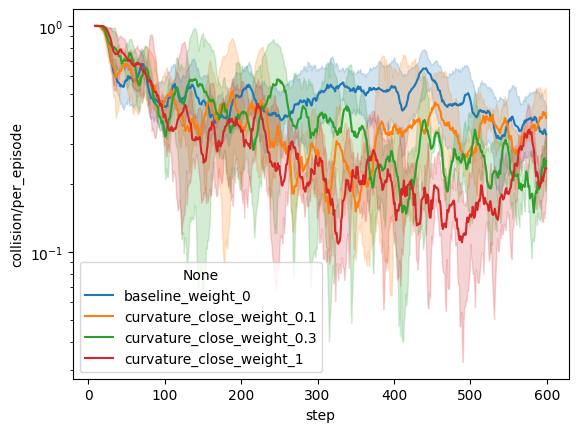

In [55]:
to_show = (
    data_pivot[data_pivot["run_category"].isin(["baseline", "curvature_close"])]
    .groupby(RUN_COLUMNS)
    .rolling(10, on="step")
    .mean()
    .reset_index()
)
sns.lineplot(
    data=to_show,
    x="step",
    y="collision/per_episode",
    hue=to_show["run_category"] + "_weight_" + to_show["aux_weight"]
).set(yscale="log")

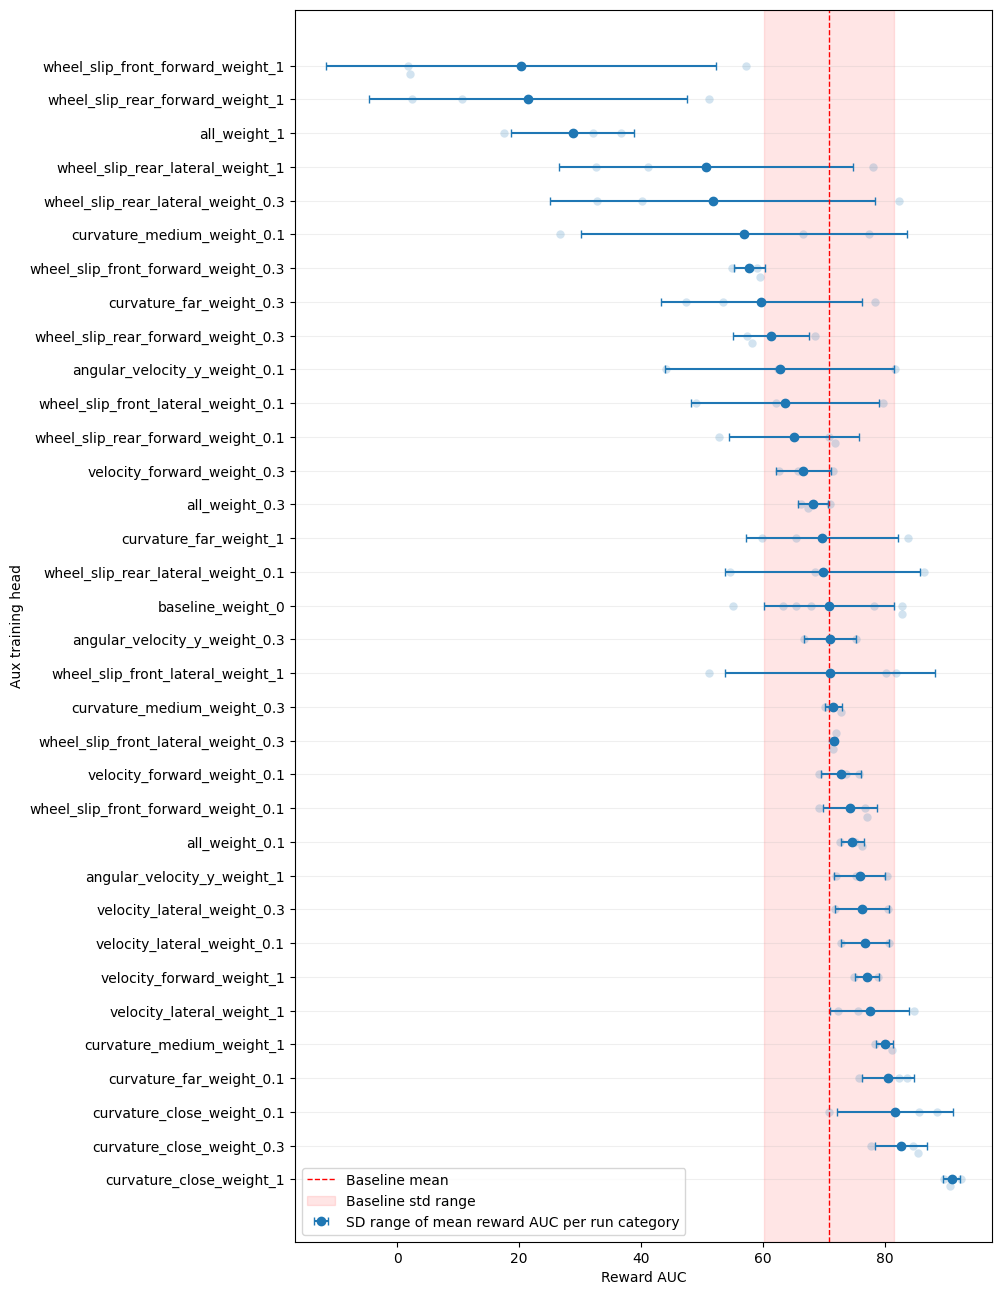

In [180]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std"]).reset_index().sort_values("mean")


base_mean = to_show[to_show["run_category"]
                    == "baseline"][STAT].mean()

plt.figure(figsize=(9, 16))


plt.errorbar(
    to_show_means["mean"],
    to_show_means["label"],
    xerr=to_show_means["std"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    y="label",
    x=STAT,
    legend=False,
    s=6,
    alpha=0.2
).set(ylabel="Aux training head", xlabel="Reward AUC")


sns.scatterplot(
    data=to_show_means,
    y="label",
    x="mean"
)



plt.grid(True, axis="y", alpha=0.2)


plt.axvline(base_mean, color="red", ls="--", lw=1, label="Baseline mean")
plt.axvspan(base_mean - to_show_means[to_show_means["label"].str.contains("baseline")]["std"].mean(),
            base_mean + to_show_means[to_show_means["label"].str.contains("baseline")]["std"].mean(),
            color="red", alpha=0.1, label="Baseline std range")


plt.legend(loc="lower left")
plt.savefig("results/figures/auc_comparison.pdf")

[Text(83.0815972222222, 0.5, 'Auxiliary training head'),
 Text(0.5, 146.5815972222222, 'Metric')]

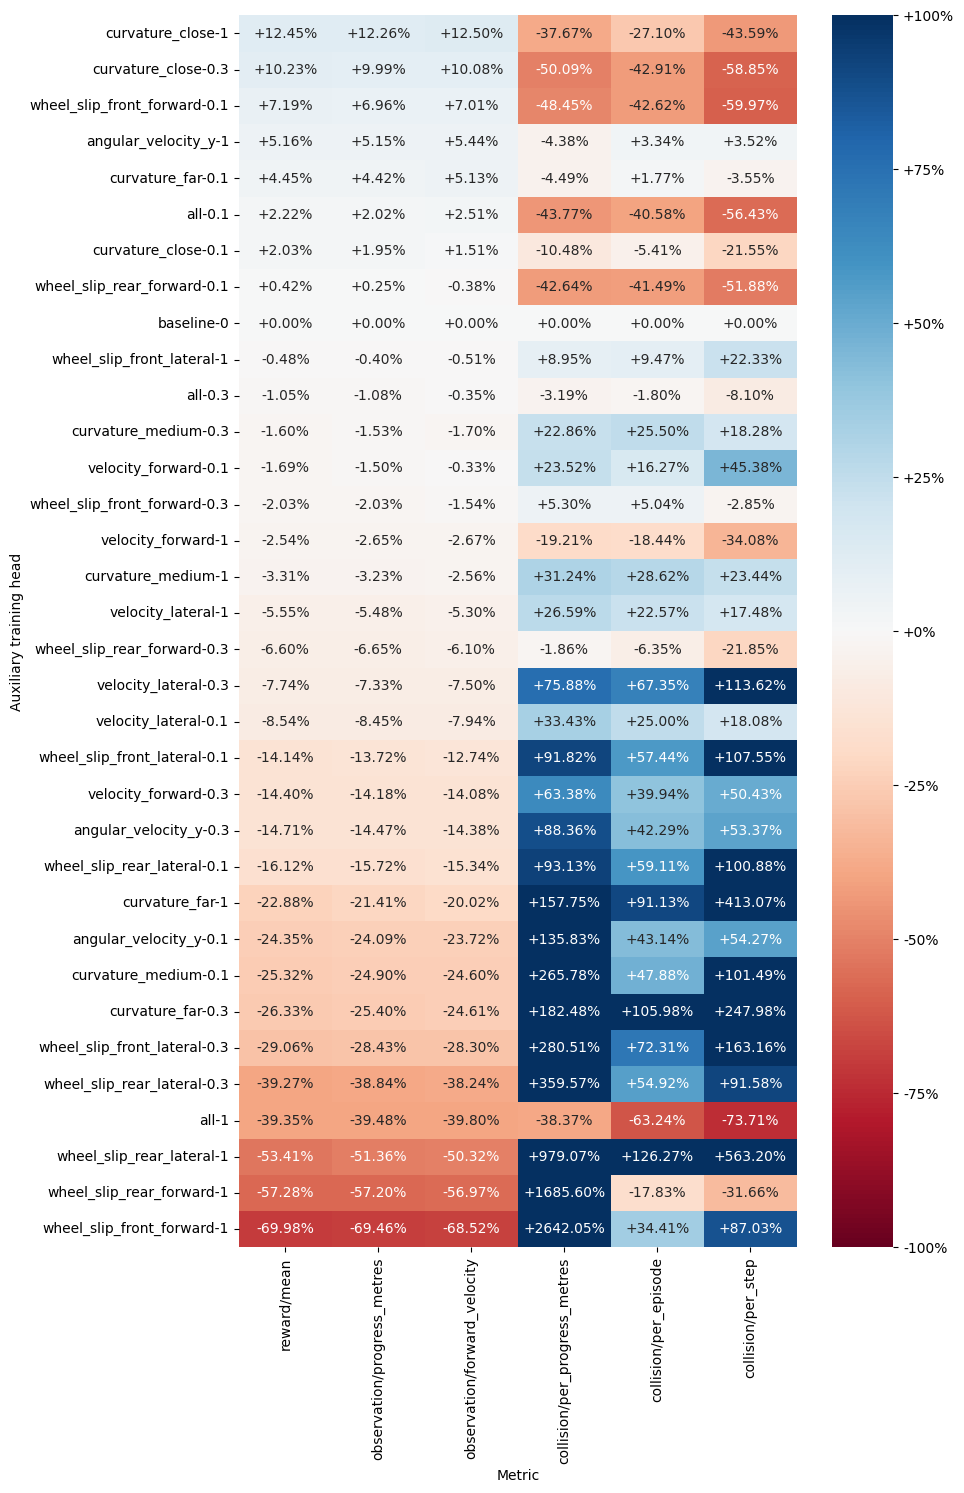

In [203]:
to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)
baseline = to_show.loc["baseline"].squeeze()

to_show = to_show.div(baseline, axis=1)
to_show -= 1
plt.figure(figsize=(9, 16))

sns.heatmap(
    to_show, 
    annot=True, 
    fmt="+.2%", 
    cmap="RdBu", 
    center=0,
    vmax=1.0,
    vmin=-1.0,
    cbar_kws={
        "format": FuncFormatter(lambda x, _: f"{x:+.0%}"),
    }
).set(ylabel="Auxiliary training head", xlabel="Metric")